# Homework 5

Inferring Population Structure

The cells below illustrate PCA and the ancestry model on a small simulated dataset. Use hpgR's functions on the course data for the assignment below.

In [1]:
library(hpgR)

set.seed(5)
toy_p <- rbind(rep(0.20, 80), rep(0.80, 80))
toy_group <- rep(c('A', 'B'), each = 12)
toy_x <- matrix(0L, nrow = 24, ncol = 80)
for (i in seq_len(nrow(toy_x))) {
  toy_x[i, ] <- simulateGenotypes(1L, toy_p[match(toy_group[i], c('A', 'B')), ])
}
stopifnot(all(toy_x %in% 0:2))


## Main functions

`genotypePCA()` centers each SNP count and divides by the Hardy–Weinberg standard deviation $\sqrt{2p(1-p)}$. `fitAdmixture()` fits the allele-draw likelihood by an EM algorithm. Read their definitions in hpgR before applying them to new data. In particular, check which quantities the functions estimate from the sample.

In [2]:
# genotypePCA() standardizes the markers; fitAdmixture() fits ancestry proportions.
# Both functions are provided by hpgR.


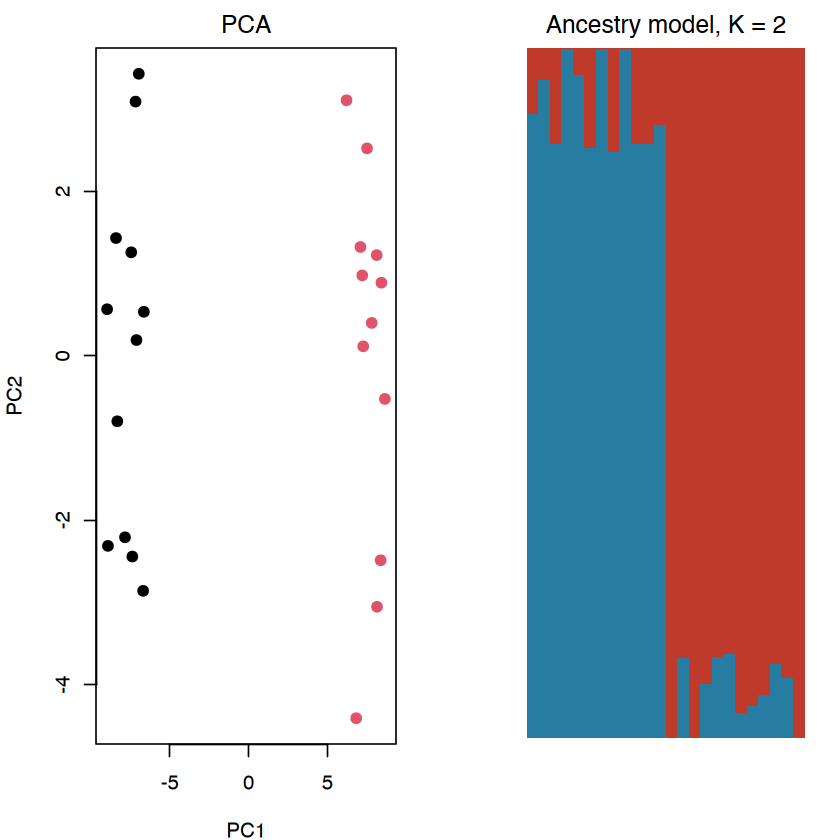

In [3]:
toy_pc <- genotypePCA(toy_x)
set.seed(5)
toy_fit <- fitAdmixture(toy_x, k = 2, scores = toy_pc$scores)
par(mfrow = c(1, 2), mar = c(4, 4, 2, 1))
plot(toy_pc$scores[, 1:2], col = as.integer(factor(toy_group)),
     pch = 19, xlab = 'PC1', ylab = 'PC2', main = 'PCA')
barplot(t(toy_fit$q), col = c('#277DA1', '#C03A2B'), border = NA,
        space = 0, axes = FALSE, main = 'Ancestry model, K = 2')
par(mfrow = c(1, 1))
stopifnot(all(diff(toy_fit$log_likelihood) > -1e-6))


## Credits

The five-population teaching question follows Hellenthal, *Handbook of Statistical Genomics* (2019), Figures 8.2–8.3, which adapt the simulation in [Lawson et al. (2012)](https://doi.org/10.1371/journal.pgen.1002453). The homework genotype matrix is a **new course simulation**, not the published matrix. For the allele-draw model, see Pritchard, *An Owner’s Guide to the Human Genome*, Chapter 3.1.

## Model and prediction

Five populations arose through splits and drift, with no admixture.

![Five-population split tree](assets/homework5_tree.png)

Tree from Hellenthal (2019), Fig. 8.2a; simulation from Lawson et al. (2012).

Define the PCA model and how SNP counts are centered and scaled. For the ancestry model, define $g_{i\ell}$, $p_{\ell k}$, $q_{ki}$, and $K$, and write the genotype distribution given $P$ and $Q$.

Before analysis, predict which groups may separate in PCs 1–2 and 3–4 and what changes for $K=2,3,5$. Explain why each model is natural for the question. The published figures' cross-validation preference for $K=2$ applies to their dataset.

*Write your models and predictions here.*

## Course data

Use [the genotype data](data/P8149_Homework_5_Structure_Data.rds). These are 125 people from A, B1, B2, C1, and C2 and 1,200 unlinked SNPs coded 0, 1, or 2. This is a new course simulation following the tree, not the matrix behind the published figures. No admixture was simulated.

- Check dimensions, labels, and genotype coding.
- Plot PCs 1–2 and 3–4. Use labels only to interpret the fitted results.
- With `set.seed(8149)`, fit the ancestry model at $K=2,3,5$. Put people in population order when plotting $Q$.
- Plot log likelihood across iterations. A larger training likelihood alone does not identify the historical number of populations.

In [4]:
courseData <- readRDS("data/P8149_Homework_5_Structure_Data.rds")

## Interpretation

Which splits appear in PCs 1–2 and 3–4? As $K$ changes, which groups share a component and which become distinct? Do mixed ancestry bars prove historical admixture? What does each model show that the other does not?

Connect claims to specific figures. Compare results with predictions and check the code, model, and prediction when they disagree.

*Write your interpretation here.*

## Submission

Submit a self-contained R Jupyter notebook exported as HTML, including your final Model and Insight answer, predictions, code, figures, and concise interpretation. A clear handwritten first part may be submitted separately. Name any AI tool used. Read the code and revise the explanation yourself.